# Patrones espaciales y temporales de los registros de la rana de ojos rojos (*Agalychnis callidryas*) en Costa Rica, según datos de ciencia ciudadana de iNaturalist

**Autor(a):** _[Jarod Salas Díaz - B97082]_

**Curso:** _[GF-0657 Programación en SIG]_

**Fecha:** 9 de octubre de 2026


## 1. Introducción

### Tema

La rana de ojos rojos (*Agalychnis callidryas*) es un anfibio arborícola
nocturno, característico de los bosques húmedos de tierras bajas de Costa
Rica. Gracias a aplicaciones de ciencia ciudadana como
[iNaturalist](https://www.inaturalist.org/), miles de personas han
fotografiado y georreferenciado observaciones de esta especie durante más
de dos décadas. Este trabajo explora ese conjunto de datos para describir
**cuándo** y **dónde** se ha registrado la especie en el país, y qué tan
confiable es esa huella de datos como reflejo de su presencia real.

### Preguntas que se responden

1. ¿Cómo ha cambiado, entre 2000 y 2025, el número de observaciones anuales
   de *A. callidryas* registradas en iNaturalist para Costa Rica?
2. ¿Existe un patrón estacional (mensual) en la frecuencia de las
   observaciones, y coincide con la época de reproducción reportada en la
   literatura?
3. ¿En qué provincias de Costa Rica se concentran los registros de la
   especie?

### Fuente de los datos

Los datos son una exportación de observaciones de *Agalychnis callidryas*
en Costa Rica del sitio iNaturalist, descargada el 9 de octubre de 2026.
Incluye observaciones de cualquier grado de calidad (`casual`, `needs_id`,
`research`); en la sección de preparación de datos se explica por qué se
usa únicamente el grado `research` para el análisis. La cita bibliográfica
completa está en la sección de referencias.

### Descripción de las variables principales

| Variable | Descripción |
|---|---|
| `observed_on` | Fecha en que se hizo la observación (reportada por quien la subió). |
| `quality_grade` | Nivel de verificación de la identificación: `casual`, `needs_id` o `research` (grado comunitario, el más confiable). |
| `latitude`, `longitude` | Coordenadas geográficas del sitio de observación (grados decimales). |
| `place_guess` | Descripción textual del lugar, escrita por quien observó (no siempre incluye la provincia). |
| `positional_accuracy` | Incertidumbre de la coordenada, en metros. |
| `identifications_count`, `num_identification_agreements`, `num_identification_disagreements` | Cantidad de identificaciones hechas por la comunidad y cuántas concuerdan o no con la especie reportada. |
| `coordinates_obscured` | Indica si iNaturalist ofuscó la coordenada real (por motivos de conservación). |
| `license_code` | Licencia bajo la cual el autor compartió la observación. |


## 2. Carga y preparación de los datos

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110


### 2.1 Lectura desde una URL

Los datos se leen directamente desde el archivo CSV alojado en el
repositorio de GitHub de esta tarea (enlace "Raw").


In [2]:
# Después de subir el CSV a su propio repositorio de GitHub, reemplace esta
# URL por la URL "Raw" de su archivo (botón "Raw" en GitHub).
url_datos = "https://raw.githubusercontent.com/TU-USUARIO/tarea-02/main/agalychnis_callidryas_costa_rica_inaturalist.csv"

df = pd.read_csv(url_datos)
df.shape


(9799, 23)

### 2.2 Exploración inicial

Se revisan las dimensiones, los tipos de dato de cada columna y las
primeras filas, para confirmar que la lectura fue correcta.


In [3]:
print(f"Filas: {df.shape[0]}, columnas: {df.shape[1]}")
df.dtypes


Filas: 9799, columnas: 23


id                                    int64
uuid                                    str
observed_on                             str
time_observed_at                        str
created_at                              str
quality_grade                           str
license_code                            str
uri                                     str
user_login                              str
user_name                               str
taxon_id                              int64
taxon_name                              str
taxon_common_name                       str
latitude                            float64
longitude                           float64
positional_accuracy                 float64
place_guess                             str
coordinates_obscured                    str
identifications_count                 int64
num_identification_agreements         int64
num_identification_disagreements      int64
sound_url                               str
photo_url                       

In [4]:
df.head(3)


,id,uuid,observed_on,time_observed_at,created_at,quality_grade,license_code,uri,user_login,user_name,taxon_id,taxon_name,taxon_common_name,latitude,longitude,positional_accuracy,place_guess,coordinates_obscured,identifications_count,num_identification_agreements,num_identification_disagreements,sound_url,photo_url
0,25161,7f97a196-bcf8-4588-8857-e05970184423,2011-03-15,NaN,2011-07-16T08:55:01-07:00,research,NaN,http://www.inaturalist.org/observations/25161,redpine,NaN,23702,Agalychnis callidryas,Red-eyed Tree Frog,8.798141,-82.969694,NaN,"Las Cruces Biological Station, Coto Brus, Cost...",false,4,4,0,NaN,https://static.inaturalist.org/photos/45380/sq...
1,27488,a213da04-6c06-40a3-913d-133f38cd681a,2009-05-15,NaN,2011-08-10T16:29:24-04:00,research,NaN,http://www.inaturalist.org/observations/27488,rahunt2,NaN,23702,Agalychnis callidryas,Red-eyed Tree Frog,10.398960,-84.135063,NaN,"Tirimbina, Costa Rica",false,4,4,0,NaN,https://static.inaturalist.org/photos/50025/sq...
2,33708,b50bd7e5-8f15-4f5a-bdde-60739a9261e7,2007-06-29,NaN,2011-10-03T18:10:29-05:00,research,NaN,http://www.inaturalist.org/observations/33708,devinedmonds,NaN,23702,Agalychnis callidryas,Red-eyed Tree Frog,10.384724,-84.041570,NaN,Costa Rica,obscured,4,4,0,NaN,https://static.inaturalist.org/photos/57354/sq...


In [5]:
# Valores faltantes por columna
df.isna().sum().sort_values(ascending=False)


sound_url                           9783
user_name                           3180
license_code                        2769
positional_accuracy                 1577
time_observed_at                     436
observed_on                           83
place_guess                           60
photo_url                             50
created_at                             0
id                                     0
uuid                                   0
quality_grade                          0
uri                                    0
user_login                             0
taxon_id                               0
longitude                              0
latitude                               0
taxon_common_name                      0
taxon_name                             0
identifications_count                  0
coordinates_obscured                   0
num_identification_disagreements       0
num_identification_agreements          0
dtype: int64

La tabla anterior muestra, entre otras cosas, que `sound_url` casi nunca
tiene datos (no se usa en este análisis), que `positional_accuracy` falta
en cerca de un 16 % de las filas, y que `place_guess` falta en muy pocas
observaciones. Estas columnas se usan más adelante, así que sus valores
faltantes se manejan en cada paso según corresponda.


### 2.3 Transformación 1 — Filtrar por grado de calidad

iNaturalist clasifica cada observación en `casual`, `needs_id` o
`research`. Solo las de grado `research` tienen una identificación de
especie verificada por la comunidad (al menos dos personas coinciden y no
hay desacuerdos sin resolver). Para que el análisis se base en
identificaciones confiables de *A. callidryas*, se conservan únicamente
las observaciones `research`.


In [6]:
conteo_calidad = df["quality_grade"].value_counts()
conteo_calidad


quality_grade
research    9206
needs_id     400
casual       193
Name: count, dtype: int64

In [7]:
df = df[df["quality_grade"] == "research"].copy()
print(f"Observaciones tras filtrar por grado 'research': {len(df)}")


Observaciones tras filtrar por grado 'research': 9206


### 2.4 Transformación 2 — Fechas válidas y columnas de año y mes

La columna `observed_on` llega como texto. Se convierte a fecha y se
descartan las filas sin fecha o con fecha anterior al año 2000 (un puñado
de registros con errores evidentes de digitación, por ejemplo años como
1969 o 1991, muy anteriores a la fundación de iNaturalist en 2008). De la
fecha válida se extraen el año y el mes de observación, que se usan en
los gráficos de tendencia y estacionalidad.


In [8]:
df["observed_on"] = pd.to_datetime(df["observed_on"], errors="coerce")

antes = len(df)
df = df.dropna(subset=["observed_on"])
df = df[df["observed_on"].dt.year >= 2000]
print(f"Filas descartadas por fecha faltante o implausible: {antes - len(df)}")

df["anio"] = df["observed_on"].dt.year
df["mes"] = df["observed_on"].dt.month
df[["observed_on", "anio", "mes"]].head(3)


Filas descartadas por fecha faltante o implausible: 8


,observed_on,anio,mes
0,2011-03-15,2011,3
1,2009-05-15,2009,5
2,2007-06-29,2007,6


### 2.5 Transformación 3 — Provincia a partir de `place_guess`

El conjunto de datos no trae una columna de provincia. El texto libre de
`place_guess` casi siempre menciona el nombre de una de las siete
provincias de Costa Rica (por ejemplo `"Heredia Province, Sarapiqui, Costa
Rica"` o `"Aguirre, Puntarenas, CR"`), así que se usa una expresión
regular para extraerla. Las observaciones en las que no se pudo
identificar una provincia (lugar descrito de forma genérica, p. ej. solo
`"Costa Rica"`, o `place_guess` faltante) se excluyen únicamente de los
análisis por provincia, no del resto del cuaderno.


In [9]:
provincias = [
    "San José", "Alajuela", "Cartago", "Heredia",
    "Guanacaste", "Puntarenas", "Limón",
]

patron = re.compile(
    "|".join(p.replace("é", "[eé]").replace("ó", "[oó]") for p in provincias),
    re.IGNORECASE,
)
normalizacion = {
    "san jose": "San José", "alajuela": "Alajuela", "cartago": "Cartago",
    "heredia": "Heredia", "guanacaste": "Guanacaste",
    "puntarenas": "Puntarenas", "limon": "Limón",
}


def extraer_provincia(texto):
    if not isinstance(texto, str):
        return None
    coincidencia = patron.search(texto)
    if coincidencia is None:
        return None
    clave = coincidencia.group(0).lower().replace("é", "e").replace("ó", "o")
    return normalizacion.get(clave)


df["provincia"] = df["place_guess"].apply(extraer_provincia)

con_provincia = df["provincia"].notna().sum()
print(
    f"Provincia identificada en {con_provincia} de {len(df)} observaciones "
    f"({con_provincia / len(df):.1%})."
)


Provincia identificada en 7991 de 9198 observaciones (86.9%).


### 2.6 Transformación 4 — Época del año (seca / lluviosa)

Para apoyar la interpretación del patrón mensual, se agrega una columna
que clasifica cada mes en época **seca** (diciembre a abril, que además
coincide con la temporada alta de turismo) o **lluviosa** (mayo a
noviembre), según la división climática habitual del Valle Central y el
Pacífico de Costa Rica.


In [10]:
meses_secos = {12, 1, 2, 3, 4}
df["epoca"] = np.where(df["mes"].isin(meses_secos), "Seca", "Lluviosa")
df[["mes", "epoca"]].drop_duplicates().sort_values("mes")


,mes,epoca
11,1,Seca
14,2,Seca
0,3,Seca
8,4,Seca
1,5,Lluviosa
2,6,Lluviosa
48,7,Lluviosa
6,8,Lluviosa
35,9,Lluviosa
9,10,Lluviosa


Con las transformaciones anteriores, el conjunto de datos queda listo para
resumir y graficar. El siguiente resumen confirma el tamaño final de cada
subconjunto que se usa más adelante.


In [11]:
print(f"Observaciones 'research' con fecha válida (2000 en adelante): {len(df)}")
print(f"  de las cuales con provincia identificada: {df['provincia'].notna().sum()}")
print(
    "  de las cuales del año 2026 (parcial, datos hasta el 9 de octubre): "
    f"{(df['anio'] == 2026).sum()}"
)


Observaciones 'research' con fecha válida (2000 en adelante): 9198
  de las cuales con provincia identificada: 7991
  de las cuales del año 2026 (parcial, datos hasta el 9 de octubre): 1591


## 3. Tabla resumen: observaciones por provincia

La siguiente tabla agrupa (`groupby`) las observaciones con provincia
identificada y calcula, para cada una, el número de observaciones, su
porcentaje del total y el número de personas distintas (`user_login`) que
las registraron.


In [12]:
resumen_provincia = (
    df.dropna(subset=["provincia"])
    .groupby("provincia")
    .agg(
        observaciones=("id", "count"),
        observadores_distintos=("user_login", "nunique"),
    )
    .sort_values("observaciones", ascending=False)
)
resumen_provincia["porcentaje"] = (
    resumen_provincia["observaciones"] / resumen_provincia["observaciones"].sum()
)

(
    resumen_provincia.style.format(
        {"observaciones": "{:,.0f}", "observadores_distintos": "{:,.0f}", "porcentaje": "{:.1%}"}
    )
    .bar(subset=["observaciones"], color="#6baed6")
    .set_caption("Observaciones de A. callidryas por provincia (grado research, 2000-2026)")
)


,observaciones,observadores_distintos,porcentaje
provincia,,,
Alajuela,"3,055","1,998",38.2%
Puntarenas,"1,637","1,172",20.5%
Limón,"1,499",987,18.8%
Heredia,"1,476",954,18.5%
Guanacaste,114,99,1.4%
San José,109,92,1.4%
Cartago,101,80,1.3%


**Qué muestra la tabla:** las observaciones no se reparten de forma
pareja entre provincias. Alajuela concentra la mayor cantidad de
registros, muy por encima de las demás, seguida de Puntarenas, Limón y
Heredia; San José, Cartago y Guanacaste —paradójicamente, donde vive gran
parte de la población humana del país— aparecen con muchas menos
observaciones. Esto es consistente con el hábitat de la especie (bosque
húmedo de tierras bajas), más extendido en la vertiente Caribe y zonas
bajas del norte y sur del Pacífico que en el Valle Central.


## 4. Gráficos

### 4.1 Pregunta 1 — Tendencia anual de observaciones (gráfico de líneas)


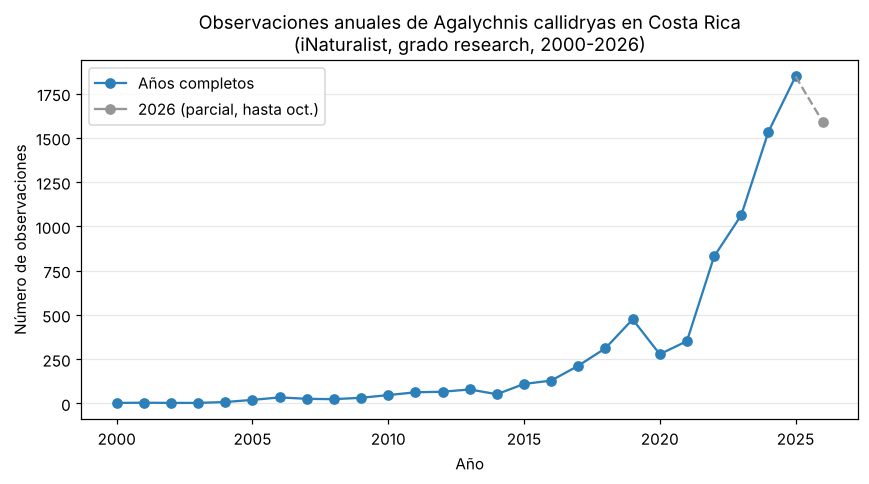

In [13]:
obs_por_anio = df.groupby("anio").size()

fig, ax = plt.subplots(figsize=(8, 4.5))

completos = obs_por_anio[obs_por_anio.index <= 2025]
ax.plot(completos.index, completos.values, marker="o", color="#2c7fb8", label="Años completos")

# El año 2026 está incompleto (datos solo hasta el 9 de octubre): se marca aparte.
if 2026 in obs_por_anio.index:
    ax.plot(
        [2025, 2026],
        [obs_por_anio[2025], obs_por_anio[2026]],
        linestyle="--",
        color="#969696",
    )
    ax.plot(2026, obs_por_anio[2026], marker="o", color="#969696", label="2026 (parcial, hasta oct.)")

ax.set_title("Observaciones anuales de Agalychnis callidryas en Costa Rica\n(iNaturalist, grado research, 2000-2026)")
ax.set_xlabel("Año")
ax.set_ylabel("Número de observaciones")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


**Interpretación:** el número de observaciones anuales se mantuvo bajo y
estable hasta mediados de la década de 2010, y luego creció de forma casi
exponencial a partir de 2017, alcanzando cerca de 1 900 observaciones en
2025. El año 2026 (barra gris discontinua) ya supera la mitad de ese total
con datos hasta solo el 9 de octubre, lo que sugiere que, de completarse,
superaría a 2025. Es improbable que esto refleje un aumento real en la
población de la especie en un período tan corto; es mucho más consistente
con el crecimiento en el número de personas que usan iNaturalist y suben
fotos de fauna en Costa Rica durante esos años (un sesgo típico de los
datos de ciencia ciudadana, que mezcla abundancia real con esfuerzo de
observación).


### 4.2 Pregunta 2 — Patrón estacional por mes (gráfico de barras)

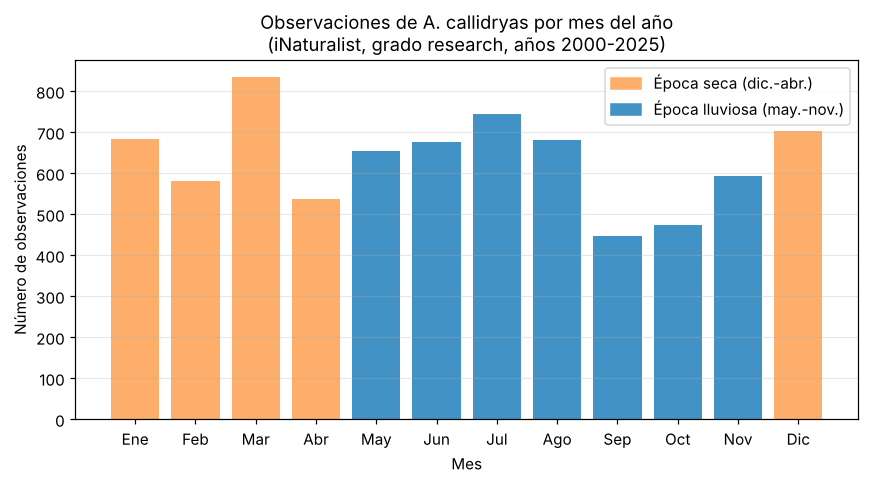

In [14]:
nombres_mes = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic",
]

# Se usan solo años completos (2000-2025) para no sesgar los meses de
# enero a octubre con el exceso de datos del año 2026, que aún no tiene
# noviembre ni diciembre.
df_completo = df[df["anio"] <= 2025]
obs_por_mes = df_completo.groupby("mes").size().reindex(range(1, 13), fill_value=0)

colores = ["#fdae6b" if m in meses_secos else "#4292c6" for m in obs_por_mes.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(nombres_mes, obs_por_mes.values, color=colores)

ax.set_title("Observaciones de A. callidryas por mes del año\n(iNaturalist, grado research, años 2000-2025)")
ax.set_xlabel("Mes")
ax.set_ylabel("Número de observaciones")

leyenda = [
    plt.Rectangle((0, 0), 1, 1, color="#fdae6b", label="Época seca (dic.-abr.)"),
    plt.Rectangle((0, 0), 1, 1, color="#4292c6", label="Época lluviosa (may.-nov.)"),
]
ax.legend(handles=leyenda)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


**Interpretación:** las observaciones ocurren en todos los meses del año,
sin una estación claramente dominante; marzo es el mes con más registros
y setiembre el de menos. Según AmphibiaWeb (s. f.), la reproducción de *A.
callidryas* se concentra en la época lluviosa (mayo-noviembre), con un
pico en junio. En estos datos, junio sí está entre los meses con más
observaciones, pero el mes con más registros de todos (marzo) cae en
plena época seca, que es también la temporada alta de turismo y de
visitas a reservas biológicas en Costa Rica. Esto apoya la idea de que el
patrón mensual observado aquí refleja, al menos en parte, cuándo hay más
personas visitando el bosque y fotografiando fauna, y no únicamente la
biología reproductiva de la especie.


### 4.3 Pregunta 3 — Distribución geográfica (gráfico de dispersión)

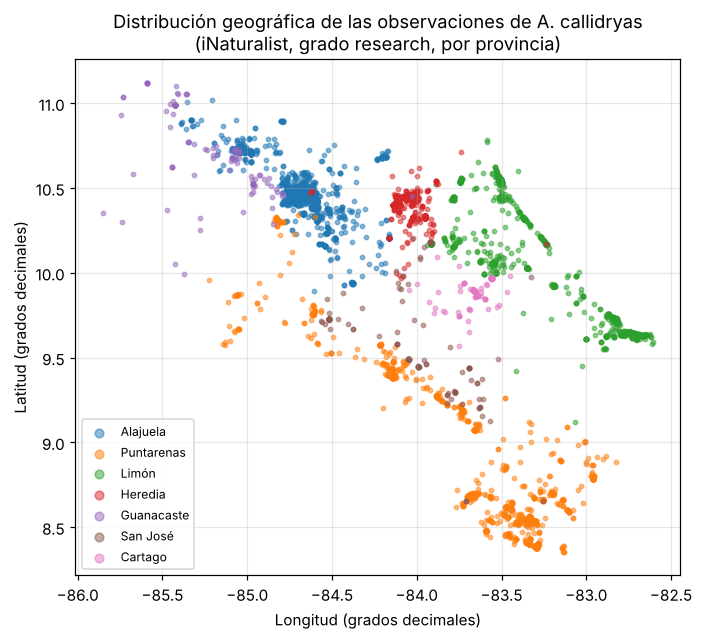

In [15]:
df_mapa = df.dropna(subset=["provincia"])
paleta = plt.get_cmap("tab10")
provincias_orden = resumen_provincia.index.tolist()

fig, ax = plt.subplots(figsize=(6.5, 7.5))
for i, prov in enumerate(provincias_orden):
    subconjunto = df_mapa[df_mapa["provincia"] == prov]
    ax.scatter(
        subconjunto["longitude"],
        subconjunto["latitude"],
        s=8,
        alpha=0.5,
        color=paleta(i),
        label=prov,
    )

ax.set_title("Distribución geográfica de las observaciones de A. callidryas\n(iNaturalist, grado research, por provincia)")
ax.set_xlabel("Longitud (grados decimales)")
ax.set_ylabel("Latitud (grados decimales)")
ax.set_aspect("equal")
ax.legend(markerscale=2, fontsize=8, loc="lower left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


**Interpretación:** los puntos trazan, a grandes rasgos, la silueta de
Costa Rica y confirman el patrón de la tabla de la sección 3: una franja
densa de observaciones (en tonos naranja y verde) recorre la vertiente
Caribe, desde Limón hasta Heredia y el norte de Alajuela, y otra
concentración clara aparece en el Pacífico sur de Puntarenas. En
contraste, el centro del país (San José, Cartago) muestra muy pocos
puntos, a pesar de ser la zona con más población humana y, por lo tanto,
más observadores potenciales; esto refuerza que la distribución
registrada responde sobre todo al hábitat de bosque húmedo de tierras
bajas de la especie, más que a dónde vive la gente.


## 5. Conclusiones

1. **Tendencia anual:** el número de observaciones registradas de *A.
   callidryas* en Costa Rica se mantuvo bajo hasta aproximadamente 2016 y
   después aumentó de forma marcada, en particular desde 2022. Es poco
   probable que este incremento refleje un cambio real en la población de
   la especie en tan pocos años; se explica mejor por el crecimiento en
   el número de usuarios de iNaturalist en el país.

2. **Estacionalidad:** no se observa una estación claramente dominante en
   el número de registros mensuales. El patrón encontrado no reproduce de
   forma nítida el pico reproductivo de la época lluviosa reportado en la
   literatura (AmphibiaWeb, s. f.); en su lugar, parece influido también
   por la temporada alta de turismo (época seca), lo que sugiere que el
   esfuerzo de observación varía a lo largo del año tanto o más que la
   actividad biológica de la rana.

3. **Distribución geográfica:** las observaciones se concentran en las
   zonas bajas y húmedas de las provincias de Alajuela, Puntarenas, Limón
   y Heredia, y son escasas en el Valle Central (San José, Cartago,
   Guanacaste), lo que coincide con el hábitat conocido de la especie más
   que con la densidad de población humana.

### Limitaciones

- Los datos de iNaturalist son de **ciencia ciudadana**: dependen de dónde
  y cuándo decide ir y fotografiar la gente, no de un muestreo diseñado
  para representar la distribución real de la especie. El aumento
  observado en el tiempo mezcla posibles cambios reales con el
  crecimiento de la plataforma.
- Alrededor de un 13 % de las observaciones no pudo asignarse a una
  provincia porque `place_guess` era demasiado genérico (p. ej. solo
  "Costa Rica") o estaba vacío; esas filas se excluyeron de la tabla y el
  mapa, lo que pudo subrepresentar ligeramente alguna zona.
- El año 2026 está incompleto (datos solo hasta el 9 de octubre de 2026),
  por lo que no es comparable directamente con los años anteriores y se
  excluyó del análisis de estacionalidad.
- Aun filtrando por grado `research`, la identificación de especie puede
  tener errores residuales, y algunas coordenadas aparecen ofuscadas por
  iNaturalist (columna `coordinates_obscured`) para proteger localidades
  sensibles, lo que introduce un pequeño ruido posicional en el mapa.


## 6. Referencias bibliográficas

AmphibiaWeb. (s. f.). *Agalychnis callidryas: Red-eyed treefrog*.
University of California, Berkeley. Recuperado el 9 de octubre de 2026, de
https://amphibiaweb.org/species/616

iNaturalist contribuyentes. (2026). *Observaciones de Agalychnis callidryas
en Costa Rica* [Conjunto de datos]. iNaturalist. Recuperado el 9 de octubre
de 2026, de https://www.inaturalist.org/taxa/23702-Agalychnis-callidryas


## 7. Declaración de uso de asistentes de inteligencia artificial

Se utilizó el asistente de IA **Claude (Anthropic)** como apoyo para:
explorar inicialmente el conjunto de datos (valores faltantes, rangos de
fechas, formato de `place_guess`); diseñar y depurar el código de limpieza
y transformación de datos con pandas; generar y ajustar el código de los
tres gráficos con matplotlib; y redactar un primer borrador del texto
interpretativo de cada sección, que después fue revisado. No se usó para
generar los datos en sí (provienen de iNaturalist) ni para inventar cifras
o resultados: todas las salidas de las celdas son el resultado real de
ejecutar el código sobre el archivo de datos adjunto.

_Antes de entregar, revise y personalice esta declaración con el detalle
real de cómo usó (o no) herramientas de IA, de acuerdo con los
lineamientos de su curso._
